# ทดสอบพยากรณ์ย้อนหลัง (back test) อุณหภูมิ ความชื้น และ Heat Index ที่สถานีใน กทม.

ย้ายมาจาก HEAT-SAFE Bangkok (NB10) เพื่อให้อยู่ร่วมกับโมดูลพยากรณ์ภัยความร้อนรายเขต (`weather_heatsafe.py`) ซึ่งใช้ค่าปรับแก้ที่ notebook นี้สร้าง — ตรรกะการวิเคราะห์เดิม เปลี่ยนแหล่งค่าวัดเป็นฐานข้อมูล wxdb

**คำถามจากทีม:** ค่าคลาดเคลื่อน ~1.3 °C บนหน้าเว็บ BURANA คือ MAE หรือ RMSE ของระยะไหน และถ้าดูเฉพาะ กทม. และวันที่ร้อนจัด ที่ล่วงหน้า 24 / 72 / 168 ชม. เป็นเท่าไร

| | |
|---|---|
| **พยากรณ์** | Open-Meteo Previous Runs API: ค่าที่ทายไว้ล่วงหน้า ≥ 24, 72, 168 ชม. (`previous_day1/3/7`) รายชั่วโมง ของ 9 โมเดลโลก + ค่าเฉลี่ยหลายโมเดล |
| **ค่าวัด** | ฐานข้อมูล wxdb (`observation_best`): METAR ดอนเมือง สุวรรณภูมิ รายชั่วโมง (IEM) + สถานี synop ของกรมอุตุนิยมวิทยา 5 แห่ง (NOAA GHCNh; ตั้งแต่ ก.ย. 2569 จาก API ของกรม) |
| **ช่วง** | 2024-01-01 – เมื่อวาน (คลังพยากรณ์ย้อนหลังเริ่ม 2024) |
| **ตัวชี้วัด** | MAE (ผิดเฉลี่ย) · RMSE (ให้น้ำหนักครั้งที่พลาดมาก) · bias (ทายสูง + / ต่ำ −) แยกตามระยะ · ทุกช่วง / ฤดูร้อน มี.ค.–พ.ค. / **วันร้อนจัด** (HI สูงสุดที่วัดได้ ≥ 42 °C = ระดับส้มขึ้นไปของ กทม.) |
| **การเตือน** | ทายวันระดับส้ม (HI สูงสุด ≥ 42) ถูกแค่ไหน: POD, FAR, CSI · ความน่าจะเป็นจากหลายโมเดล (สัดส่วนโมเดลที่ทาย ≥ 42) และความน่าเชื่อถือ (Brier, reliability) |

**Outputs:** `resources/heatsafe_calibration.json` (ค่าปรับแก้ที่ระบบพยากรณ์ใช้จริง) · `analysis/heat_forecast_backtest_summary.md` · `analysis/heat_backtest/` (ตารางคะแนนและรูป) · `outputs/heat_backtest/fc_backtest_hourly.parquet` (คู่ข้อมูลรายชั่วโมง ไม่ขึ้น GitHub)

In [1]:
import os
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ.setdefault("WXDB_READONLY", "1")
import json
import time
import warnings
warnings.filterwarnings("ignore")
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import matplotlib as mpl
from matplotlib import font_manager as fm
import wxdb

# ฟอนต์ไทยสำหรับรูป (เหมือนชุด notebook ของ HEAT-SAFE)
_font = next((f for f in ["Sarabun", "TH Sarabun New", "Thonburi", "Tahoma", "Noto Sans Thai"]
              if f in {x.name for x in fm.fontManager.ttflist}), None)
if _font:
    mpl.rcParams["font.family"] = _font
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 11})
P = ROOT / "analysis" / "heat_backtest"                # ตารางคะแนนและรูป (ขึ้น GitHub — งานประยุกต์ เช่น สไลด์ของ HEAT-SAFE อ่านจากที่นี่)
BIG = ROOT / "outputs" / "heat_backtest"               # คู่ข้อมูลรายชั่วโมง (ไฟล์ใหญ่ ไม่ขึ้น GitHub)
P.mkdir(parents=True, exist_ok=True)
BIG.mkdir(parents=True, exist_ok=True)
CALIB = ROOT / "resources" / "heatsafe_calibration.json"
SUMMARY = ROOT / "analysis" / "heat_forecast_backtest_summary.md"


def save(fig, name):
    p = P / f"{name}.png"
    fig.savefig(p)
    return p


CONFIG = {
    "api": "https://previous-runs-api.open-meteo.com/v1/forecast",
    "start": "2024-01-01",
    "end": str((pd.Timestamp.today() - pd.Timedelta(days=1)).date()),
    "leads": {1: "24 ชม.", 3: "72 ชม.", 7: "168 ชม."},
    "models": {"ecmwf_ifs025": "ECMWF IFS", "ecmwf_aifs025_single": "ECMWF AIFS", "gfs_global": "NOAA GFS",
               "icon_global": "DWD ICON", "gem_global": "ECCC GEM", "jma_gsm": "JMA GSM",
               "meteofrance_arpege_world": "MF ARPEGE", "ukmo_global_deterministic_10km": "UKMO UM",
               "cma_grapes_global": "CMA GRAPES"},
    # site_id ใน wxdb: METAR (IEM) ดอนเมือง สุวรรณภูมิ + synop ของกรมอุตุนิยมวิทยา
    "stations": ["metar:VTBD", "metar:VTBS", "tmd:48455", "tmd:48453", "tmd:48454", "tmd:48456", "tmd:48429"],
    "names": {"metar:VTBD": "สนามบินดอนเมือง (METAR)", "metar:VTBS": "สนามบินสุวรรณภูมิ (METAR)"},
    "hot_months": [3, 4, 5],
    "orange": 42.0,                      # HI ระดับส้ม (อันตราย) ของ กทม.
    "min_models_ens": 3,
    "qc_dev": 6.0,                       # °C: ห่างจากมัธยฐานของโมเดลอื่นเกินนี้ = คลังพยากรณ์เสีย (ตัดทิ้ง)                 # ค่าเฉลี่ย/ความน่าจะเป็นหลายโมเดล ต้องมีอย่างน้อย 3 โมเดล
}
RAW = ROOT / "data" / "prev_runs_bkk"                 # cache รายไตรมาส (ไม่ขึ้น GitHub)
RAW.mkdir(parents=True, exist_ok=True)


def rh_from_dew(t, td):
    return (100 * np.exp(17.625 * td / (243.04 + td)) / np.exp(17.625 * t / (243.04 + t))).clip(0, 100)


def heat_index_c(t_c, rh):
    """Heat Index (NWS/Rothfusz) — สมการเดียวกับ weather_heatsafe.py และ NB05 ของ HEAT-SAFE"""
    t = np.asarray(t_c, dtype=float) * 9 / 5 + 32
    rh = np.asarray(rh, dtype=float)
    hi = 0.5 * (t + 61 + (t - 68) * 1.2 + rh * 0.094)
    full = (-42.379 + 2.04901523 * t + 10.14333127 * rh - 0.22475541 * t * rh - 6.83783e-3 * t ** 2
            - 5.481717e-2 * rh ** 2 + 1.22874e-3 * t ** 2 * rh + 8.5282e-4 * t * rh ** 2 - 1.99e-6 * t ** 2 * rh ** 2)
    adj1 = ((13 - rh) / 4) * np.sqrt(np.clip((17 - np.abs(t - 95)) / 17, 0, None))
    full = np.where((rh < 13) & (t >= 80) & (t <= 112), full - adj1, full)
    full = np.where((rh > 85) & (t >= 80) & (t <= 87), full + ((rh - 85) / 10) * ((87 - t) / 5), full)
    return (np.where((hi + t) / 2 >= 80, full, hi) - 32) * 5 / 9

## 1) สถานีและค่าวัดรายชั่วโมง (wxdb)

In [2]:
con = wxdb.connect(tables=["observation", "site"])
sids = "', '".join(CONFIG["stations"])
st = con.sql(f"SELECT site_id AS station_id, name AS name_th, lat, lon FROM site WHERE site_id IN ('{sids}')").df()
st["name_th"] = st.station_id.map(CONFIG["names"]).fillna(st.name_th)
st = st.set_index("station_id").loc[CONFIG["stations"]].reset_index()
ob = con.sql(f"""SELECT site_id AS station_id, time, var_id, value FROM observation_best
                WHERE site_id IN ('{sids}') AND period_h = 0 AND var_id IN ('t2m', 'rh2m')
                  AND time >= TIMESTAMP '{CONFIG["start"]}' - INTERVAL 7 HOUR""").df()
obs = (ob.pivot_table(index=["station_id", "time"], columns="var_id", values="value").reset_index()
       .rename(columns={"t2m": "temp", "rh2m": "rh"}))
obs["time"] = obs.time + pd.Timedelta(hours=7)                       # UTC → เวลาไทย (เหมือนพยากรณ์)
obs = obs[(obs.time >= CONFIG["start"]) & (obs.time.dt.minute == 0)]
obs = obs.dropna(subset=["temp", "rh"]).drop_duplicates(["station_id", "time"])
obs["hi"] = heat_index_c(obs.temp, obs.rh)
span = obs.groupby("station_id").time.agg(["min", "max"])
st["first"], st["last"] = st.station_id.map(span["min"]), st.station_id.map(span["max"])
print(f"ค่าวัด: {len(obs):,} สถานี-ชั่วโมง | {obs.time.min():%Y-%m-%d} – {obs.time.max():%Y-%m-%d}")
st.assign(n_obs=st.station_id.map(obs.station_id.value_counts()))


ค่าวัด: 103,018 สถานี-ชั่วโมง | 2024-01-01 – 2026-10-26


,station_id,name_th,lat,lon,first,last,n_obs
0,metar:VTBD,สนามบินดอนเมือง (METAR),13.91920,100.60500,2024-01-01 07:00:00,2026-10-26 09:00:00,24676
1,metar:VTBS,สนามบินสุวรรณภูมิ (METAR),13.69000,100.75010,2024-01-01 07:00:00,2026-10-26 09:00:00,24681
2,tmd:48455,สถานีกรุงเทพมหานคร,13.72639,100.56000,2024-01-01 01:00:00,2026-10-24 22:00:00,19642
3,tmd:48453,สถานีกรุงเทพฯ บางนา สกษ.,13.66639,100.60611,2024-01-01 01:00:00,2026-10-24 22:00:00,20688
4,tmd:48454,สถานีกรุงเทพฯ ท่าเรือคลองเตย,13.70694,100.56805,2024-01-01 07:00:00,2026-10-24 19:00:00,5060
5,tmd:48456,สถานีสนามบินดอนเมือง,13.91917,100.60500,2026-09-27 10:00:00,2026-10-24 22:00:00,197
6,tmd:48429,สนามบินสุวรรณภูมิ,13.68639,100.76750,2024-01-01 01:00:00,2026-10-24 22:00:00,8074


## 2) พยากรณ์ย้อนหลังจาก Open-Meteo Previous Runs (cache รายไตรมาส)

In [3]:
VARS = [f"{v}_previous_day{d}" for v in ("temperature_2m", "relative_humidity_2m") for d in CONFIG["leads"]]


def fetch_quarter(q0):
    """ทุกสถานีในคำขอเดียว 1 ไตรมาส → DataFrame ยาว (สถานี, เวลา UTC→ไทย, โมเดล, ระยะ, T, RH)"""
    q1 = min(q0 + pd.offsets.QuarterEnd(0), pd.Timestamp(CONFIG["end"]))
    dest = RAW / f"prev_runs_{q0:%Y%m}.parquet"
    complete = q1 < pd.Timestamp.today().normalize() - pd.Timedelta(days=10) and q1 == q0 + pd.offsets.QuarterEnd(0)
    if dest.exists() and complete:
        return pd.read_parquet(dest)
    for attempt in range(6):
        r = requests.get(CONFIG["api"], params={
            "latitude": ",".join(f"{x:.4f}" for x in st.lat), "longitude": ",".join(f"{x:.4f}" for x in st.lon),
            "hourly": ",".join(VARS), "models": ",".join(CONFIG["models"]), "timezone": "GMT",
            "start_date": str(q0.date()), "end_date": str(q1.date())}, timeout=600)
        if r.status_code == 429 or (r.status_code == 400 and "limit" in r.text.lower()):
            time.sleep(70)
            continue
        r.raise_for_status()
        try:
            js = r.json()
            break
        except ValueError:                             # คำตอบไม่ใช่ JSON (ขัดข้องชั่วคราว) → รอแล้วลองใหม่
            time.sleep(70)
    else:
        raise RuntimeError(f"Previous Runs ไม่ตอบ: {q0:%Y-%m}")
    js = js if isinstance(js, list) else [js]
    rows = []
    for sid, j in zip(st.station_id, js):
        h = j["hourly"]
        t = pd.to_datetime(h["time"]) + pd.Timedelta(hours=7)                 # UTC → เวลาไทย
        for k, name in CONFIG["models"].items():
            for d in CONFIG["leads"]:
                tt = h.get(f"temperature_2m_previous_day{d}_{k}")
                rr = h.get(f"relative_humidity_2m_previous_day{d}_{k}")
                if tt is None or all(v is None for v in tt):
                    continue
                rows.append(pd.DataFrame({"station_id": sid, "time": t, "model": name, "lead_d": d,
                                          "temp_fc": pd.to_numeric(pd.Series(tt), errors="coerce"),
                                          "rh_fc": pd.to_numeric(pd.Series(rr if rr else [None] * len(t)), errors="coerce")}))
    df = pd.concat(rows, ignore_index=True).dropna(subset=["temp_fc"]) if rows else pd.DataFrame()
    df.to_parquet(dest, index=False)
    return df


quarters = pd.date_range(CONFIG["start"], CONFIG["end"], freq="QS")
with ThreadPoolExecutor(2) as ex:
    fc = pd.concat(list(ex.map(fetch_quarter, quarters)), ignore_index=True)
# ตรวจคุณภาพคลังพยากรณ์: ค่าที่ห่างจากมัธยฐานของโมเดลอื่น (ชั่วโมง/สถานี/ระยะเดียวกัน) เกิน qc_dev °C = ข้อมูลเสีย
# (เช่น CMA GRAPES เม.ย.–มิ.ย. 2024 ต่ำกว่าจริง ~9 °C) → ตัดทิ้งก่อนคำนวณทุกอย่าง
med = fc.groupby(["station_id", "time", "lead_d"]).temp_fc.transform("median")
bad = (fc.temp_fc - med).abs() > CONFIG["qc_dev"]
qc_log = fc[bad].assign(q=fc.time.dt.to_period("Q").astype(str)).groupby(["model", "q"]).size().rename("ตัดทิ้ง (ชั่วโมง)")
print(f"ตัดค่าพยากรณ์ผิดปกติ {int(bad.sum()):,} ค่า ({100 * bad.mean():.2f}%)")
print(qc_log[qc_log > 100].to_string())
fc = fc[~bad]
fc["hi_fc"] = heat_index_c(fc.temp_fc, fc.rh_fc)
print(f"พยากรณ์: {len(fc):,} แถว | {fc.time.min():%Y-%m-%d} – {fc.time.max():%Y-%m-%d}")
fc.groupby(["model", "lead_d"]).size().unstack()

ตัดค่าพยากรณ์ผิดปกติ 9,527 ค่า (0.26%)
model       q     
CMA GRAPES  2024Q2    5612
ECCC GEM    2024Q1     103
            2025Q1     815
            2025Q4     364
            2026Q1     521
            2026Q2     203
            2026Q3     111
NOAA GFS    2025Q1     358
            2026Q1     140
            2026Q3     109
พยากรณ์: 3,625,643 แถว | 2024-01-01 – 2026-10-26


lead_d,1,3,7
model,,,
CMA GRAPES,155714.0,152015.0,91622.0
DWD ICON,169219.0,168889.0,NaN
ECCC GEM,168485.0,167819.0,167518.0
ECMWF AIFS,103320.0,102984.0,100073.0
ECMWF IFS,167121.0,166770.0,166083.0
JMA GSM,172860.0,170559.0,172821.0
MF ARPEGE,169129.0,169256.0,NaN
NOAA GFS,169716.0,169214.0,168206.0
UKMO UM,104782.0,111468.0,NaN


## 3) จับคู่พยากรณ์–ค่าวัด + ค่าเฉลี่ยหลายโมเดล

In [4]:
# ค่าเฉลี่ยหลายโมเดล (ทุกโมเดลที่มีค่าในชั่วโมงนั้น ≥ min_models_ens)
ens = fc.groupby(["station_id", "time", "lead_d"]).agg(temp_fc=("temp_fc", "mean"), rh_fc=("rh_fc", "mean"),
                                                       n_models=("temp_fc", "count")).reset_index()
ens = ens[ens.n_models >= CONFIG["min_models_ens"]].drop(columns="n_models")
ens["hi_fc"] = heat_index_c(ens.temp_fc, ens.rh_fc)
ens["model"] = "ค่าเฉลี่ยหลายโมเดล"
pairs = pd.concat([fc, ens], ignore_index=True).merge(obs, on=["station_id", "time"], how="inner")
pairs["lead"] = pairs.lead_d.map(CONFIG["leads"])
pairs["date"] = pairs.time.dt.normalize()
pairs["hot_season"] = pairs.time.dt.month.isin(CONFIG["hot_months"])
# วันร้อนจัด: HI สูงสุดที่วัดได้ของวันนั้นที่สถานีนั้น ≥ 42 (ต้องมีค่าวัด ≥ 18 ชม.)
od = obs.assign(date=obs.time.dt.normalize()).groupby(["station_id", "date"]).agg(hi_obs_max=("hi", "max"), n=("hi", "size"))
hot_days = od[(od.n >= 18) & (od.hi_obs_max >= CONFIG["orange"])].index
pairs["hot_day"] = pd.MultiIndex.from_frame(pairs[["station_id", "date"]]).isin(hot_days)
pairs.to_parquet(BIG / "fc_backtest_hourly.parquet", index=False)
print(f"คู่พยากรณ์–ค่าวัด {len(pairs):,} | วันร้อนจัด (สถานี-วัน) {len(hot_days):,}")

คู่พยากรณ์–ค่าวัด 2,480,379 | วันร้อนจัด (สถานี-วัน) 698


## 4) MAE / RMSE / bias แยกตามระยะ: ทุกช่วง · ฤดูร้อน · วันร้อนจัด
ทุกค่าเป็นของ **สถานีใน กทม./รอบเขต เท่านั้น** และ **แยกระยะ 24 / 72 / 168 ชม.** (ไม่รวมกัน)

In [5]:
def scores(g, v):
    e = (g[f"{v}_fc"] - g[v]).dropna()
    return pd.Series({"n": len(e), "MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "bias": e.mean()})


subsets = {"ทุกช่วง": pairs, "ฤดูร้อน มี.ค.–พ.ค.": pairs[pairs.hot_season], "วันร้อนจัด (HI ≥ 42)": pairs[pairs.hot_day]}
sc = []
for sname, g in subsets.items():
    for v, vname in [("temp", "อุณหภูมิ"), ("rh", "ความชื้น"), ("hi", "Heat Index")]:
        s = g.groupby(["model", "lead_d"]).apply(lambda x: scores(x, v)).reset_index()
        sc.append(s.assign(subset=sname, variable=vname))
sc = pd.concat(sc, ignore_index=True)
sc["lead"] = sc.lead_d.map(CONFIG["leads"])
# ต้องมีครบ 3 ระยะและคู่พอ จึงเทียบกันได้
sc = sc[sc.n >= 200]
sc.round(2).to_csv(P / "fc_backtest_scores.csv", index=False)
best = (sc[(sc.variable == "อุณหภูมิ")].pivot_table(index=["subset", "model"], columns="lead", values=["MAE", "RMSE"])
        .round(2))
best

MAE                  RMSE         \
lead                                    168 ชม. 24 ชม. 72 ชม. 168 ชม. 24 ชม.   
subset               model                                                     
ทุกช่วง              CMA GRAPES            1.66   1.49   1.60    2.15   1.89   
                     DWD ICON               NaN   1.42   1.44     NaN   1.75   
                     ECCC GEM              2.22   2.01   2.09    2.79   2.51   
                     ECMWF AIFS            1.26   1.16   1.17    1.60   1.49   
                     ECMWF IFS             2.05   1.70   1.80    2.49   2.07   
                     JMA GSM               1.71   1.59   1.62    2.14   1.99   
                     MF ARPEGE              NaN   1.29   1.45     NaN   1.71   
                     NOAA GFS              1.73   1.39   1.52    2.29   1.87   
                     UKMO UM                NaN   1.39   1.48     NaN   1.83   
                     ค่าเฉลี่ยหลายโมเดล    1.51   1.18   1.21    1.89   1.48   
ฤดูร้อน มี.ค.–พ.ค.   CMA GRAPES            1.36   1.26   1.26    1.92   1.70   
                     DWD ICON               NaN   1.37   1.34     NaN   1.68   
                     ECCC GEM              1.78   1.73   1.68    2.32   2.21   
                     ECMWF AIFS            1.18   1.08   1.07    1.53   1.40   
                     ECMWF IFS             1.77   1.45   1.55    2.24   1.83   
                     JMA GSM               1.75   1.68   1.68    2.22   2.12   
                     MF ARPEGE              NaN   1.17   1.27     NaN   1.63   
                     NOAA GFS              1.43   1.16   1.28    2.07   1.78   
                     UKMO UM                NaN   1.32   1.32     NaN   1.78   
                     ค่าเฉลี่ยหลายโมเดล    1.23   1.04   1.05    1.64   1.36   
วันร้อนจัด (HI ≥ 42) CMA GRAPES            1.52   1.58   1.59    2.00   1.97   
                     DWD ICON               NaN   1.39   1.39     NaN   1.69   
                     ECCC GEM              2.25   1.90   1.99    2.84   2.39   
                     ECMWF AIFS            1.26   1.11   1.12    1.60   1.43   
                     ECMWF IFS             2.16   1.75   1.94    2.64   2.13   
                     JMA GSM               1.95   1.90   1.93    2.42   2.34   
                     MF ARPEGE              NaN   1.26   1.38     NaN   1.73   
                     NOAA GFS              1.58   1.18   1.35    2.20   1.73   
                     UKMO UM                NaN   1.34   1.37     NaN   1.83   
                     ค่าเฉลี่ยหลายโมเดล    1.56   1.20   1.23    1.96   1.51   

                                                
lead                                    72 ชม.  
subset               model                      
ทุกช่วง              CMA GRAPES           2.03  
                     DWD ICON             1.80  
                     ECCC GEM             2.63  
                     ECMWF AIFS           1.50  
                     ECMWF IFS            2.21  
                     JMA GSM              2.03  
                     MF ARPEGE            1.92  
                     NOAA GFS             2.03  
                     UKMO UM              1.94  
                     ค่าเฉลี่ยหลายโมเดล   1.53  
ฤดูร้อน มี.ค.–พ.ค.   CMA GRAPES           1.74  
                     DWD ICON             1.68  
                     ECCC GEM             2.16  
                     ECMWF AIFS           1.40  
                     ECMWF IFS            1.97  
                     JMA GSM              2.12  
                     MF ARPEGE            1.80  
                     NOAA GFS             1.89  
                     UKMO UM              1.78  
                     ค่าเฉลี่ยหลายโมเดล   1.41  
วันร้อนจัด (HI ≥ 42) CMA GRAPES           2.04  
                     DWD ICON             1.71  
                     ECCC GEM             2.52  
                     ECMWF AIFS           1.45  
                     ECMWF IFS            2.38  
                     JMA GSM   

## 5) รายวัน: Tmax, Tmin, HI สูงสุด และการทายวันระดับส้ม (HI สูงสุด ≥ 42)
ใช้เฉพาะวันที่มีทั้งพยากรณ์และค่าวัด ≥ 18 ชั่วโมง · ความน่าจะเป็น = สัดส่วนโมเดลที่ทาย HI สูงสุด ≥ 42

In [6]:
dly = pairs.groupby(["station_id", "date", "model", "lead_d"]).agg(
    n=("temp", "size"), tmax=("temp", "max"), tmin=("temp", "min"), hi_max=("hi", "max"),
    tmax_fc=("temp_fc", "max"), tmin_fc=("temp_fc", "min"), hi_max_fc=("hi_fc", "max")).reset_index()
dly = dly[dly.n >= 18]
dly["obs_orange"] = dly.hi_max >= CONFIG["orange"]
dly["fc_orange"] = dly.hi_max_fc >= CONFIG["orange"]
dly["lead"] = dly.lead_d.map(CONFIG["leads"])


def cat(g):
    a = (g.fc_orange & g.obs_orange).sum()
    b = (g.fc_orange & ~g.obs_orange).sum()
    c = (~g.fc_orange & g.obs_orange).sum()
    d = (~g.fc_orange & ~g.obs_orange).sum()
    return pd.Series({"days": len(g), "obs_orange_days": a + c, "POD": a / (a + c) if a + c else np.nan,
                      "FAR": b / (a + b) if a + b else np.nan, "CSI": a / (a + b + c) if a + b + c else np.nan,
                      "freq_bias": (a + b) / (a + c) if a + c else np.nan,
                      "MAE_tmax": (g.tmax_fc - g.tmax).abs().mean(), "RMSE_tmax": np.sqrt(((g.tmax_fc - g.tmax) ** 2).mean()),
                      "MAE_tmin": (g.tmin_fc - g.tmin).abs().mean(), "RMSE_tmin": np.sqrt(((g.tmin_fc - g.tmin) ** 2).mean()),
                      "MAE_himax": (g.hi_max_fc - g.hi_max).abs().mean(), "RMSE_himax": np.sqrt(((g.hi_max_fc - g.hi_max) ** 2).mean()),
                      "bias_himax": (g.hi_max_fc - g.hi_max).mean()})


hot = dly[dly.date.dt.month.isin(CONFIG["hot_months"])]
alert = hot.groupby(["model", "lead_d"]).apply(cat).reset_index()
alert["lead"] = alert.lead_d.map(CONFIG["leads"])
alert = alert[alert.days >= 100]
alert.round(3).to_csv(P / "fc_alert_scores.csv", index=False)
alert.pivot_table(index="model", columns="lead", values=["POD", "FAR", "CSI", "MAE_himax", "RMSE_himax"]).round(2)

CSI                   FAR               MAE_himax  \
lead               168 ชม. 24 ชม. 72 ชม. 168 ชม. 24 ชม. 72 ชม.   168 ชม.   
model                                                                      
CMA GRAPES            0.18   0.11   0.09    0.25   0.19   0.19      2.79   
DWD ICON               NaN   0.37   0.42     NaN   0.25   0.31       NaN   
ECCC GEM              0.43   0.42   0.44    0.41   0.27   0.31      2.29   
ECMWF AIFS            0.41   0.47   0.40    0.49   0.43   0.48      2.03   
ECMWF IFS             0.22   0.21   0.23    0.34   0.18   0.18      2.95   
JMA GSM               0.13   0.14   0.14    0.37   0.24   0.27      3.32   
MF ARPEGE              NaN   0.50   0.47     NaN   0.30   0.36       NaN   
NOAA GFS              0.09   0.14   0.11    0.12   0.11   0.15      3.39   
UKMO UM                NaN   0.02   0.00     NaN   0.00    NaN       NaN   
ค่าเฉลี่ยหลายโมเดล    0.19   0.23   0.23    0.25   0.11   0.17      2.45   

                                     POD               RMSE_himax         \
lead               24 ชม. 72 ชม. 168 ชม. 24 ชม. 72 ชม.    168 ชม. 24 ชม.   
model                                                                      
CMA GRAPES           2.90   2.87    0.20   0.12   0.09       3.48   3.62   
DWD ICON             2.08   1.98     NaN   0.42   0.51        NaN   2.70   
ECCC GEM             2.31   2.22    0.60   0.50   0.55       2.93   3.17   
ECMWF AIFS           1.78   1.92    0.69   0.73   0.63       2.54   2.22   
ECMWF IFS            2.76   2.71    0.25   0.22   0.24       3.79   3.53   
JMA GSM              3.27   3.20    0.14   0.15   0.15       4.17   4.20   
MF ARPEGE            1.84   1.94     NaN   0.63   0.64        NaN   2.38   
NOAA GFS             2.97   3.27    0.09   0.14   0.12       4.14   3.63   
UKMO UM              2.86   2.74     NaN   0.02   0.00        NaN   3.54   
ค่าเฉลี่ยหลายโมเดล   2.32   2.24    0.20   0.24   0.24       3.14   3.03   

                           
lead               72 ชม.  
model                      
CMA GRAPES           3.58  
DWD ICON             2.57  
ECCC GEM             3.03  
ECMWF AIFS           2.44  
ECMWF IFS            3.43  
JMA GSM              4.06  
MF ARPEGE            2.45  
NOAA GFS             3.99  
UKMO UM              3.48  
ค่าเฉลี่ยหลายโมเดล   2.91

### ปรับเกณฑ์ฝั่งพยากรณ์ (เพราะพยากรณ์ HI ต่ำกว่าจริงในวันร้อน): เลือกเกณฑ์ที่ CSI สูงสุดจากฤดูร้อน 2024–2025 แล้วทดสอบกับฤดูร้อน 2026 (ไม่ได้ใช้เลือก)

In [7]:
ensd = hot[hot.model == "ค่าเฉลี่ยหลายโมเดล"].copy()
train, test = ensd[ensd.date.dt.year <= 2025], ensd[ensd.date.dt.year >= 2026]
thr_rows = []
for d, g in train.groupby("lead_d"):
    best_thr, best_csi = None, -1
    for thr in np.arange(36, 44.01, 0.5):
        csi = cat(g.assign(fc_orange=g.hi_max_fc >= thr)).CSI
        if csi > best_csi:
            best_thr, best_csi = thr, csi
    gt = test[test.lead_d == d]
    s42, sb = cat(gt), cat(gt.assign(fc_orange=gt.hi_max_fc >= best_thr))
    thr_rows.append({"lead": CONFIG["leads"][d], "lead_d": d, "เกณฑ์ที่เลือก (°C)": best_thr, "CSI ฝึก 2024–25": best_csi,
                     "ทดสอบ 2026 วันส้มจริง": int(s42.obs_orange_days),
                     "POD@42": s42.POD, "FAR@42": s42.FAR, "CSI@42": s42.CSI,
                     "POD@เกณฑ์ใหม่": sb.POD, "FAR@เกณฑ์ใหม่": sb.FAR, "CSI@เกณฑ์ใหม่": sb.CSI})
thr_tab = pd.DataFrame(thr_rows)
thr_tab.round(2).to_csv(P / "fc_alert_threshold.csv", index=False)
thr_tab.round(2)

,lead,lead_d,เกณฑ์ที่เลือก (°C),CSI ฝึก 2024–25,ทดสอบ 2026 วันส้มจริง,POD@42,FAR@42,CSI@42,POD@เกณฑ์ใหม่,FAR@เกณฑ์ใหม่,CSI@เกณฑ์ใหม่
0,24 ชม.,1,39.5,0.56,148,0.11,0.06,0.11,0.73,0.40,0.49
1,72 ชม.,3,39.5,0.55,148,0.07,0.17,0.07,0.86,0.41,0.54
2,168 ชม.,7,39.0,0.50,148,0.13,0.27,0.12,0.90,0.43,0.53


In [8]:
# ความน่าจะเป็นจากหลายโมเดล: สัดส่วนโมเดล (ไม่รวมค่าเฉลี่ย) ที่ทาย HI สูงสุด ≥ 42 → ความน่าเชื่อถือ
mm = hot[hot.model != "ค่าเฉลี่ยหลายโมเดล"].groupby(["station_id", "date", "lead_d"]).agg(
    p=("fc_orange", "mean"), k=("fc_orange", "size"), obs=("obs_orange", "first")).reset_index()
mm = mm[mm.k >= CONFIG["min_models_ens"]]
mm["p_bin"] = pd.cut(mm.p, [-0.01, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0], labels=["0–10%", "10–30%", "30–50%", "50–70%", "70–90%", "90–100%"])
rel = mm.groupby(["lead_d", "p_bin"], observed=False).agg(days=("obs", "size"), p_mean=("p", "mean"), obs_freq=("obs", "mean")).reset_index()
rel["lead"] = rel.lead_d.map(CONFIG["leads"])
brier = mm.groupby("lead_d").apply(lambda g: pd.Series({
    "brier": ((g.p - g.obs) ** 2).mean(), "brier_clim": ((g.obs.mean() - g.obs) ** 2).mean(), "days": len(g), "models_mean": g.k.mean()})).reset_index()
brier["BSS"] = 1 - brier.brier / brier.brier_clim
brier["lead"] = brier.lead_d.map(CONFIG["leads"])
rel.round(3).to_csv(P / "fc_reliability.csv", index=False)
brier.round(3)

,lead_d,brier,brier_clim,days,models_mean,BSS,lead
0,1,0.242,0.246,920.0,8.093,0.019,24 ชม.
1,3,0.240,0.246,920.0,8.117,0.025,72 ชม.
2,7,0.271,0.246,920.0,5.307,-0.102,168 ชม.


## 6) รูป

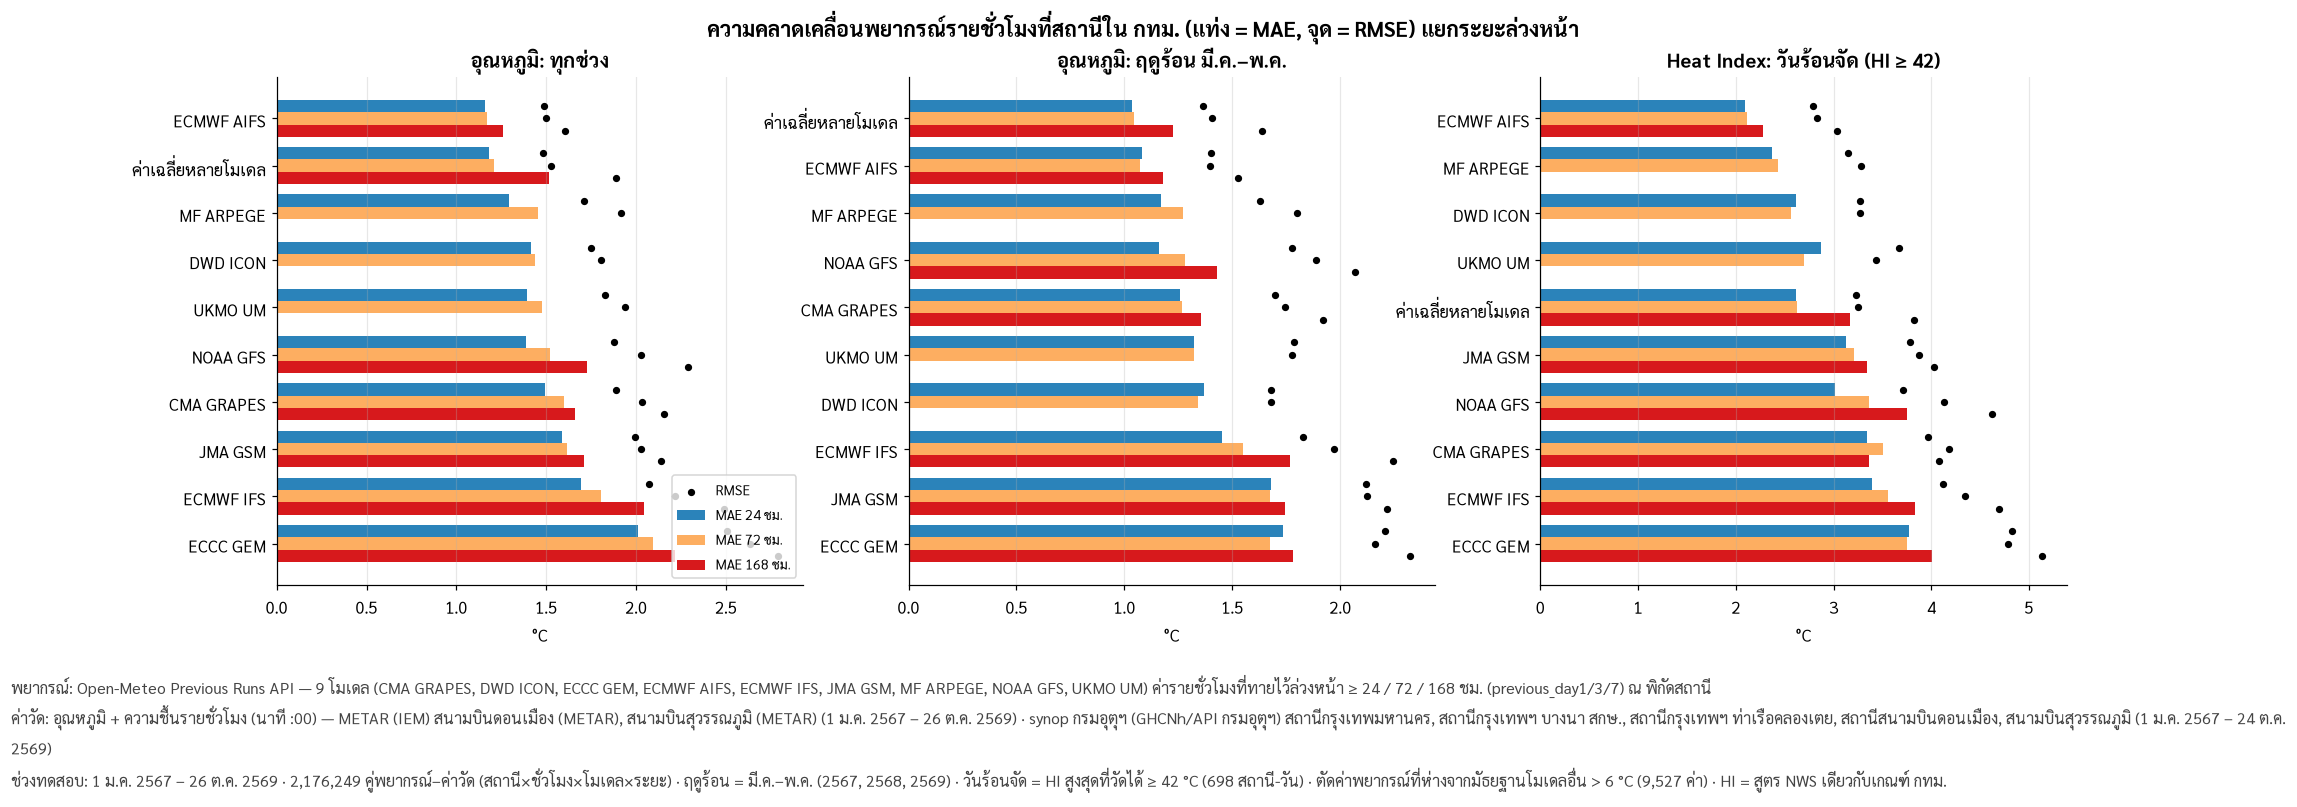

In [9]:
LC = {"24 ชม.": "#2b83ba", "72 ชม.": "#fdae61", "168 ชม.": "#d7191c"}
TH_MON = ["", "ม.ค.", "ก.พ.", "มี.ค.", "เม.ย.", "พ.ค.", "มิ.ย.", "ก.ค.", "ส.ค.", "ก.ย.", "ต.ค.", "พ.ย.", "ธ.ค."]
thd = lambda d: f"{d.day} {TH_MON[d.month]} {d.year + 543}"
# แหล่งข้อมูลและช่วงเวลา (คำนวณจากข้อมูลจริง) — ใส่ใต้รูปทุกรูป
used = pairs[pairs.model != "ค่าเฉลี่ยหลายโมเดล"]
op = used.groupby(used.station_id.str.split(":").str[0]).time.agg(["min", "max"])
stn_txt = " · ".join(f"{'METAR (IEM)' if k == 'metar' else 'synop กรมอุตุฯ (GHCNh/API กรมอุตุฯ)'} {', '.join(st[st.station_id.str.startswith(k + ':')].name_th)} ({thd(r['min'])} – {thd(r['max'])})"
                     for k, r in op.iterrows())
hs_years = sorted(used[used.hot_season].time.dt.year.unique())
DATA_NOTE = (
    f"พยากรณ์: Open-Meteo Previous Runs API — {used.model.nunique()} โมเดล ({', '.join(sorted(used.model.unique()))}) "
    f"ค่ารายชั่วโมงที่ทายไว้ล่วงหน้า ≥ 24 / 72 / 168 ชม. (previous_day1/3/7) ณ พิกัดสถานี\n"
    f"ค่าวัด: อุณหภูมิ + ความชื้นรายชั่วโมง (นาที :00) — {stn_txt}\n"
    f"ช่วงทดสอบ: {thd(used.time.min())} – {thd(used.time.max())} · {len(used):,} คู่พยากรณ์–ค่าวัด (สถานี×ชั่วโมง×โมเดล×ระยะ) · "
    f"ฤดูร้อน = มี.ค.–พ.ค. ({', '.join(str(y + 543) for y in hs_years)}) · วันร้อนจัด = HI สูงสุดที่วัดได้ ≥ {CONFIG['orange']:.0f} °C ({len(hot_days):,} สถานี-วัน) · "
    f"ตัดค่าพยากรณ์ที่ห่างจากมัธยฐานโมเดลอื่น > {CONFIG['qc_dev']:.0f} °C ({int(bad.sum()):,} ค่า) · HI = สูตร NWS เดียวกับเกณฑ์ กทม."
)


def add_note(fig, text=DATA_NOTE, y=-0.02):
    fig.text(0.01, y, text, fontsize=10.5, color="#444", va="top", ha="left", linespacing=1.5, wrap=True)

order_leads = list(CONFIG["leads"].values())
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, (sname, sub) in zip(axes, [("ทุกช่วง", "อุณหภูมิ"), ("ฤดูร้อน มี.ค.–พ.ค.", "อุณหภูมิ"), ("วันร้อนจัด (HI ≥ 42)", "Heat Index")]):
    s = sc[(sc.subset == sname) & (sc.variable == sub)]
    piv = s.pivot_table(index="model", columns="lead", values="MAE").reindex(columns=order_leads)
    piv = piv.loc[piv.mean(axis=1).sort_values().index]
    rm = s.pivot_table(index="model", columns="lead", values="RMSE").reindex(index=piv.index, columns=order_leads)
    y = np.arange(len(piv))
    for i, l in enumerate(order_leads):
        ax.barh(y + (i - 1) * 0.26, piv[l], 0.26, color=LC[l], label=f"MAE {l}")
        ax.scatter(rm[l], y + (i - 1) * 0.26, color="k", s=14, zorder=3, label="RMSE" if i == 0 else None)
    ax.set_yticks(y)
    ax.set_yticklabels(piv.index)
    ax.invert_yaxis()
    ax.set_xlabel("°C")
    ax.set_title(f"{sub}: {sname}")
    ax.grid(axis="x", alpha=0.3)
axes[0].legend(fontsize=9, loc="lower right")
fig.suptitle("ความคลาดเคลื่อนพยากรณ์รายชั่วโมงที่สถานีใน กทม. (แท่ง = MAE, จุด = RMSE) แยกระยะล่วงหน้า", fontsize=14, weight="bold")
add_note(fig)
fig_err = save(fig, "backtest_errors")
plt.show()

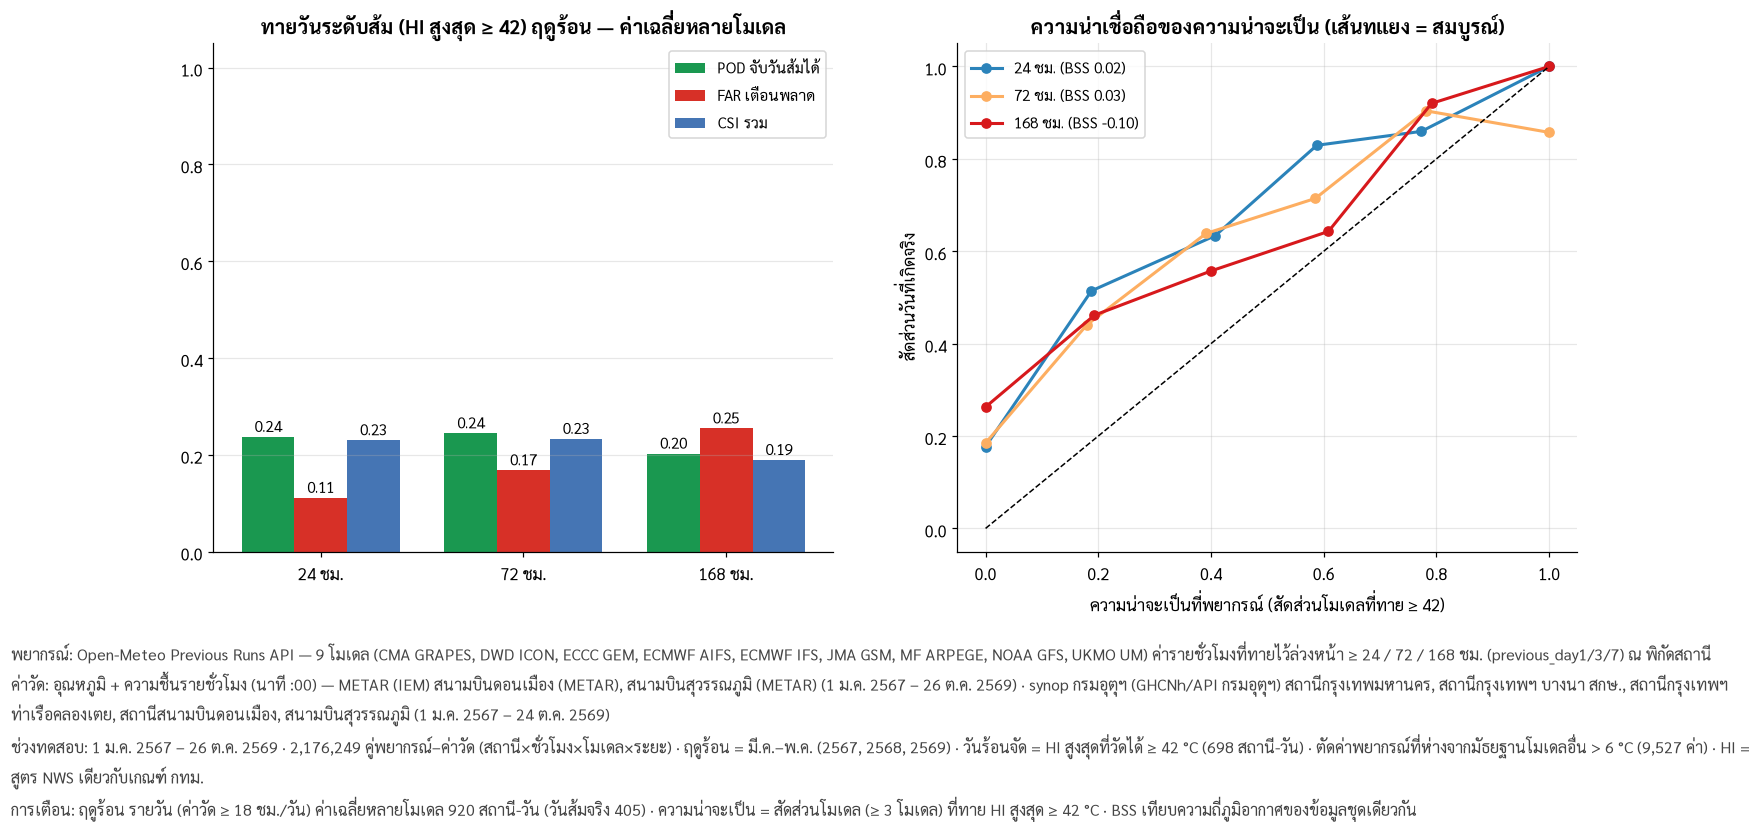

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
a = alert[alert.model == "ค่าเฉลี่ยหลายโมเดล"].set_index("lead").reindex(order_leads)
x = np.arange(len(order_leads))
for i, (k, c) in enumerate([("POD", "#1a9850"), ("FAR", "#d73027"), ("CSI", "#4575b4")]):
    axes[0].bar(x + (i - 1) * 0.26, a[k], 0.26, color=c, label={"POD": "POD จับวันส้มได้", "FAR": "FAR เตือนพลาด", "CSI": "CSI รวม"}[k])
    for xi, v in zip(x, a[k]):
        axes[0].text(xi + (i - 1) * 0.26, v + 0.01, f"{v:.2f}", ha="center", fontsize=10)
axes[0].set_xticks(x)
axes[0].set_xticklabels(order_leads)
axes[0].set_ylim(0, 1.05)
axes[0].set_title(f"ทายวันระดับส้ม (HI สูงสุด ≥ {CONFIG['orange']:.0f}) ฤดูร้อน — ค่าเฉลี่ยหลายโมเดล")
axes[0].legend(fontsize=10)
axes[0].grid(axis="y", alpha=0.3)
for l in order_leads:
    r = rel[(rel.lead == l) & (rel.days >= 10)]
    axes[1].plot(r.p_mean, r.obs_freq, marker="o", color=LC[l], lw=2, label=f"{l} (BSS {brier.set_index('lead').BSS.get(l, np.nan):.2f})")
axes[1].plot([0, 1], [0, 1], color="k", ls="--", lw=1)
axes[1].set_xlabel("ความน่าจะเป็นที่พยากรณ์ (สัดส่วนโมเดลที่ทาย ≥ 42)")
axes[1].set_ylabel("สัดส่วนวันที่เกิดจริง")
axes[1].set_title("ความน่าเชื่อถือของความน่าจะเป็น (เส้นทแยง = สมบูรณ์)")
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
add_note(fig, DATA_NOTE + f"\nการเตือน: ฤดูร้อน รายวัน (ค่าวัด ≥ 18 ชม./วัน) ค่าเฉลี่ยหลายโมเดล {int(alert[alert.model == 'ค่าเฉลี่ยหลายโมเดล'].days.max()):,} สถานี-วัน "
         f"(วันส้มจริง {int(alert[alert.model == 'ค่าเฉลี่ยหลายโมเดล'].obs_orange_days.max()):,}) · "
         f"ความน่าจะเป็น = สัดส่วนโมเดล (≥ {CONFIG['min_models_ens']} โมเดล) ที่ทาย HI สูงสุด ≥ {CONFIG['orange']:.0f} °C · BSS เทียบความถี่ภูมิอากาศของข้อมูลชุดเดียวกัน")
fig_alert = save(fig, "alert_skill")
plt.show()

## 7) ส่งออกค่าปรับแก้ (calibration) ให้โมดูลพยากรณ์ภัยความร้อนรายเขต (`resources/heatsafe_calibration.json`)
bias ของ HI สูงสุดรายวัน (ฤดูร้อน) ต่อโมเดลต่อระยะ — ระบบพยากรณ์ลบ bias นี้ออกก่อนเทียบเกณฑ์ กทม. · ระยะที่ไม่มีใช้ค่าระยะใกล้ที่สุด

In [11]:
cal_models = alert[alert.model != "ค่าเฉลี่ยหลายโมเดล"].pivot_table(index="model", columns="lead_d", values="bias_himax")
cal_models = cal_models.T.reindex(range(1, 8)).interpolate(limit_direction="both").T          # ระยะ 1–7 วัน
ens_row = sc[(sc.model == "ค่าเฉลี่ยหลายโมเดล")]
calib = {
    "generated": pd.Timestamp.now(tz="Asia/Bangkok").isoformat(timespec="minutes"),
    "source": "HEAT-SAFE Bangkok (โครงการวิจัย วช. 2570) — ทดสอบย้อนหลังใน BURANA (analysis/heat_forecast_backtest.ipynb)",
    "method": "Open-Meteo Previous Runs (≥24/72/168 h) vs hourly obs at Bangkok stations (wxdb: METAR via IEM, TMD synop via GHCNh/TMD API); bias = mean(forecast − observed) of daily max Heat Index, Mar–May",
    "period": f"{CONFIG['start']} – {CONFIG['end']}",
    "stations": st.station_id.tolist(),
    "thresholds_bma": {"green": 27.0, "yellow": 33.0, "orange": 42.0, "red": 52.0},
    "bias_himax_by_model_leadday": {m: {str(d): round(float(v), 2) for d, v in r.items()} for m, r in cal_models.iterrows()},
    "skill_multimodel": {
        r.lead: {"temp_MAE": round(float(r.MAE), 2), "temp_RMSE": round(float(r.RMSE), 2)}
        for r in ens_row[(ens_row.subset == "ทุกช่วง") & (ens_row.variable == "อุณหภูมิ")].itertuples()},
    "skill_hi_hotdays": {
        r.lead: {"MAE": round(float(r.MAE), 2), "RMSE": round(float(r.RMSE), 2), "bias": round(float(r.bias), 2)}
        for r in ens_row[(ens_row.subset == "วันร้อนจัด (HI ≥ 42)") & (ens_row.variable == "Heat Index")].itertuples()},
    "alert_orange": {r.lead: {"POD": round(float(r.POD), 2), "FAR": round(float(r.FAR), 2), "CSI": round(float(r.CSI), 2)}
                     for r in alert[alert.model == "ค่าเฉลี่ยหลายโมเดล"].itertuples()},
    "brier_skill": {r.lead: round(float(r.BSS), 2) for r in brier.itertuples()},
}
CALIB.write_text(json.dumps(calib, ensure_ascii=False, indent=1) + "\n", encoding="utf-8")
cal_models.round(2)

lead_d,1,2,3,4,5,6,7
model,,,,,,,
CMA GRAPES,-2.64,-2.58,-2.53,-2.46,-2.40,-2.33,-2.27
DWD ICON,-1.24,-0.96,-0.68,-0.68,-0.68,-0.68,-0.68
ECCC GEM,-1.38,-1.17,-0.96,-0.83,-0.70,-0.57,-0.44
ECMWF AIFS,0.10,0.24,0.38,0.37,0.37,0.36,0.36
ECMWF IFS,-2.32,-2.24,-2.17,-2.15,-2.14,-2.12,-2.11
JMA GSM,-2.92,-2.87,-2.82,-2.83,-2.83,-2.84,-2.85
MF ARPEGE,-0.62,-0.46,-0.30,-0.30,-0.30,-0.30,-0.30
NOAA GFS,-2.70,-2.82,-2.95,-2.98,-3.01,-3.04,-3.07
UKMO UM,-2.56,-2.52,-2.48,-2.48,-2.48,-2.48,-2.48


In [12]:
t24 = sc[(sc.subset == "ทุกช่วง") & (sc.variable == "อุณหภูมิ") & (sc.model == "ค่าเฉลี่ยหลายโมเดล")].set_index("lead")
thd = sc[(sc.subset == "วันร้อนจัด (HI ≥ 42)") & (sc.variable == "Heat Index") & (sc.model == "ค่าเฉลี่ยหลายโมเดล")].set_index("lead")
aa = alert[alert.model == "ค่าเฉลี่ยหลายโมเดล"].set_index("lead")
def write_summary(topic, done, metrics, observations, outputs, next_steps):
    rel = lambda p: str(Path(p).relative_to(ROOT)) if str(p).startswith(str(ROOT)) else str(p)  # noqa: E731
    lines = [f"# {topic}", f"Generated: {pd.Timestamp.now(tz='Asia/Bangkok'):%Y-%m-%d %H:%M}",
             "", "## What was done", *[f"- {x}" for x in done],
             "", "## Headline metrics", "| Metric | Value |", "|---|---|", *[f"| {k} | {v} |" for k, v in metrics.items()],
             "", "## Notable observations", *[f"- {x}" for x in observations],
             "", "## Outputs produced", *[f"- {rel(x)}" for x in outputs],
             "", "## Recommended next steps", *[f"- {x}" for x in next_steps], ""]
    SUMMARY.write_text("\n".join(lines), encoding="utf-8")
    return "\n".join(lines)


summary = write_summary(
    "Heat forecast back test at Bangkok stations (24/72/168 h)",
    done=[f"Open-Meteo Previous Runs {len(CONFIG['models'])} โมเดล (ล่วงหน้า ≥ 24/72/168 ชม.) รายชั่วโมง {CONFIG['start']} – {CONFIG['end']} ที่ {len(st)} สถานีใน กทม./รอบเขต",
          "จับคู่กับค่าวัดรายชั่วโมง (wxdb: METAR + synop กรมอุตุฯ) → MAE, RMSE, bias ของอุณหภูมิ ความชื้น HI แยกระยะ: ทุกช่วง / ฤดูร้อน / วันร้อนจัด (HI ≥ 42)",
          "ทายวันระดับส้มรายวัน: POD/FAR/CSI และความน่าจะเป็นจากหลายโมเดล (Brier, reliability)"],
    metrics={
        "คู่พยากรณ์–ค่าวัด (ชั่วโมง)": f"{len(pairs):,}",
        **{f"อุณหภูมิ ค่าเฉลี่ยหลายโมเดล {l}: MAE / RMSE": f"{t24.MAE.get(l, np.nan):.2f} / {t24.RMSE.get(l, np.nan):.2f} °C" for l in order_leads},
        **{f"HI วันร้อนจัด ค่าเฉลี่ยหลายโมเดล {l}: MAE / RMSE / bias": f"{thd.MAE.get(l, np.nan):.2f} / {thd.RMSE.get(l, np.nan):.2f} / {thd.bias.get(l, np.nan):+.2f} °C" for l in order_leads},
        **{f"ทายวันส้ม {l}: POD / FAR / CSI": f"{aa.POD.get(l, np.nan):.2f} / {aa.FAR.get(l, np.nan):.2f} / {aa.CSI.get(l, np.nan):.2f}" for l in order_leads},
        **{f"Brier skill (ความน่าจะเป็นหลายโมเดล) {r.lead}": f"{r.BSS:.2f}" for r in brier.itertuples()},
        **{f"เกณฑ์พยากรณ์ใหม่ {r.lead} (ทดสอบ 2026): POD / FAR / CSI": f"≥ {r['เกณฑ์ที่เลือก (°C)']:.1f} °C → {r['POD@เกณฑ์ใหม่']:.2f} / {r['FAR@เกณฑ์ใหม่']:.2f} / {r['CSI@เกณฑ์ใหม่']:.2f} (เทียบ @42: {r['POD@42']:.2f} / {r['FAR@42']:.2f} / {r['CSI@42']:.2f})" for _, r in thr_tab.iterrows()},
    },
    observations=[f"ตัดค่าพยากรณ์ผิดปกติ {int(bad.sum()):,} ค่า (ห่างจากมัธยฐานโมเดลอื่น > {CONFIG['qc_dev']:.0f} °C) ส่วนใหญ่ CMA GRAPES เม.ย.–มิ.ย. 2024",
                  "ค่าเว็บ BURANA (~1.3 °C) = MAE อุณหภูมิราย 3 ชม. สถานีทั่วประเทศ 30 วันล่าสุด แยกระยะ — ตารางนี้เป็นเฉพาะ กทม. ย้อนหลังตั้งแต่ 2024",
                  "MAE = ผิดเฉลี่ย · RMSE ≥ MAE เสมอ ยิ่งห่างกันมาก = มีบางครั้งที่พลาดมาก",
                  "ค่าเฉลี่ยหลายโมเดลที่ 168 ชม. มีโมเดลน้อยกว่า (ICON, ARPEGE, UKMO ไม่มีระยะนี้ในคลังย้อนหลัง)",
                  "โมเดลโลกกริด 9–28 กม. → สถานีใน กทม. หลายแห่งตกกริดเดียวกัน ความต่างระหว่างเขตมาจากค่าวัด ไม่ใช่จากพยากรณ์"],
    outputs=[CALIB, BIG / "fc_backtest_hourly.parquet", P / "fc_backtest_scores.csv", P / "fc_alert_scores.csv", P / "fc_reliability.csv", P / "fc_alert_threshold.csv", fig_err, fig_alert],
    next_steps=["ปรับแก้ bias ของพยากรณ์ด้วยค่าวัดย้อนหลัง (bias correction) ก่อนใช้กับเกณฑ์ 42 °C",
                "ทดสอบ TMD WRF 2 กม. เมื่อมีคลังย้อนหลังพอ (ตาราง forecast_point)"],
)
print(summary)

# Heat forecast back test at Bangkok stations (24/72/168 h)
Generated: 2026-10-26 10:07

## What was done
- Open-Meteo Previous Runs 9 โมเดล (ล่วงหน้า ≥ 24/72/168 ชม.) รายชั่วโมง 2024-01-01 – 2026-10-25 ที่ 7 สถานีใน กทม./รอบเขต
- จับคู่กับค่าวัดรายชั่วโมง (wxdb: METAR + synop กรมอุตุฯ) → MAE, RMSE, bias ของอุณหภูมิ ความชื้น HI แยกระยะ: ทุกช่วง / ฤดูร้อน / วันร้อนจัด (HI ≥ 42)
- ทายวันระดับส้มรายวัน: POD/FAR/CSI และความน่าจะเป็นจากหลายโมเดล (Brier, reliability)

## Headline metrics
| Metric | Value |
|---|---|
| คู่พยากรณ์–ค่าวัด (ชั่วโมง) | 2,480,379 |
| อุณหภูมิ ค่าเฉลี่ยหลายโมเดล 24 ชม.: MAE / RMSE | 1.18 / 1.48 °C |
| อุณหภูมิ ค่าเฉลี่ยหลายโมเดล 72 ชม.: MAE / RMSE | 1.21 / 1.53 °C |
| อุณหภูมิ ค่าเฉลี่ยหลายโมเดล 168 ชม.: MAE / RMSE | 1.51 / 1.89 °C |
| HI วันร้อนจัด ค่าเฉลี่ยหลายโมเดล 24 ชม.: MAE / RMSE / bias | 2.62 / 3.23 / -1.74 °C |
| HI วันร้อนจัด ค่าเฉลี่ยหลายโมเดล 72 ชม.: MAE / RMSE / bias | 2.63 / 3.25 / -1.65 °C |
| HI วันร้อนจัด ค่าเฉลี่ยหลายโมเดล 168 ชม.: MAE / RMSE / bi